# Chapter 5 notebook: sampled focusing and geometric phase

**Topic IDs:** `ms-08-metalenses` and `ms-06-polarization`.
This notebook contains **two explicitly separate models**: a scalar homogeneous
angular-spectrum calculation of a cylindrical line focus, and analytical
Jones matrices for ideal anisotropic elements. The library-based aperture field
uses Chapter 5's periodic-cell coefficients as a local approximation. It is not
a full-wave finite metalens. The Jones model is not a polarization simulation
of the TE ridges. Download the full source bundle to retain their dependencies.

In [1]:
from pathlib import Path
from dataclasses import replace,asdict
import sys,json,csv,hashlib,platform,html
import numpy as np
import scipy,matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=next((p for p in [Path.cwd(),*list(Path.cwd().parents)[:3]] if (p/'simulations/metasurface_synthesis.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('Extract the Chapter 5 source bundle, preserving simulations/, data/, and notebooks/.')
sys.path.insert(0,str(ROOT/'simulations'))
from unit_cell_te import Cell,solve_cell,sample_ey,phase_error_deg
from metasurface_synthesis import solve_supercell,staircase_coefficients,select_widths,angular_spectrum_1d,rotated_jones,line_fwhm,SOLVER_VERSION
DATA=ROOT/'data/chapter-05';DATA.mkdir(parents=True,exist_ok=True)
def table(headers,rows):
    def escape(x):return html.escape(f'{x:.7g}' if isinstance(x,(float,np.floating)) else str(x))
    display(HTML('<table><thead><tr>'+''.join('<th>'+escape(x)+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escape(x)+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
plt.rcParams.update({'figure.dpi':125,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Python',platform.python_version(),'NumPy',np.__version__,'SciPy',scipy.__version__,'Matplotlib',matplotlib.__version__)

# Editable scalar aperture parameters.
WAVELENGTH_UM=1.55;OUTPUT_INDEX=1.5;FOCAL_DISTANCE_UM=30.
PITCH_UM=.65;N_APERTURE_CELLS=48;APERTURE_UM=PITCH_UM*N_APERTURE_CELLS
DX_UM=.10;N_FFT=2048;FOCUS_WINDOW_HALF_UM=1.;FOCAL_COMPARE_HALF_UM=4.
if not isinstance(N_APERTURE_CELLS,(int,np.integer)) or N_APERTURE_CELLS<2:
    raise ValueError('Use at least two whole aperture cells.')
if not all(np.isfinite(v) and v>0 for v in [WAVELENGTH_UM,OUTPUT_INDEX,FOCAL_DISTANCE_UM,PITCH_UM]):
    raise ValueError('Wavelength, output index, focal distance, and pitch must be finite and positive.')
REFERENCE=Cell(period_um=PITCH_UM,wavelength_um=WAVELENGTH_UM,n_substrate=OUTPUT_INDEX)
REFERENCE.validate()

def require_matching_library(parameters, reference, phase_references, label):
    """Reject reuse outside the saved TE library's experiment and face references."""
    expected=asdict(reference)
    keys=('period_um','wavelength_um','n_ridge','n_gap','n_incident','n_substrate','angle_deg')
    mismatches=[]
    for key in keys:
        actual=parameters.get(key) if isinstance(parameters,dict) else None
        if actual is None or not np.isfinite(actual) or not np.isclose(actual,expected[key],rtol=1e-12,atol=1e-12):
            mismatches.append(f'{key}: saved {actual!r}, requested {expected[key]!r}')
    if phase_references.get('r')!='z=0' or phase_references.get('t')!='z=height':
        mismatches.append('reflection/transmission must be referenced to z=0/z=height')
    if mismatches:
        raise ValueError(f"{label} is incompatible with this experiment: "+'; '.join(mismatches)+
                         '. Generate a matching library before changing its pitch, wavelength, materials, or incidence.')

data=json.loads((DATA/'beam-steering.json').read_text(encoding='utf-8'))
library_metadata=data['metadata']
require_matching_library(library_metadata.get('library_parameters',{}),REFERENCE,
                         library_metadata.get('library_phase_references',{}),'Saved Chapter 5 library')
if (library_metadata.get('time_convention')!='exp(-i omega t)' or
        library_metadata.get('spatial_convention')!='exp(i k.r)'):
    raise ValueError('Saved Chapter 5 library uses incompatible phasor conventions.')
rows=data['extended_library']
print('Aperture width',APERTURE_UM,'um; nominal line-focus distance',FOCAL_DISTANCE_UM,'um')

Python 3.12.1 NumPy 2.4.6 SciPy 1.18.1 Matplotlib 3.11.1
Aperture width 31.200000000000003 um; nominal line-focus distance 30.0 um


## 1. Derive and sample a cylindrical lens phase

For normal incidence, the target outgoing wave has equal accumulated phase at
$(x,z)=(0,f)$ when $\phi(x)=-k_t[\sqrt{x^2+f^2}-f]$.
The paraxial form is $-k_tx^2/(2f)$. The exact scalar phase is used here.
The finite aperture is one-dimensional, so the focus is a line along $y$.
Compute a continuous ideal aperture, a pitch-wise sampled phase aperture, and
a local-library aperture. A fixed grid of global phase offsets minimizes the
library selection RMS; no propagated focal metric is used in that selection.

Scalar aperture model,FWHM (um),Peak / fixed ideal peak,Fixed-window line intensity / aperture width,Fixed-window / total modeled line intensity
continuous,0.9705966,1,0.8737406,0.8802246
sampled,0.9824115,0.9135391,0.8104493,0.8939227
local_library,0.9849398,0.5502845,0.489163,0.8940118


All fixed-window integrals use the same physical +/- 1.0 um boundaries, with interpolated endpoints.


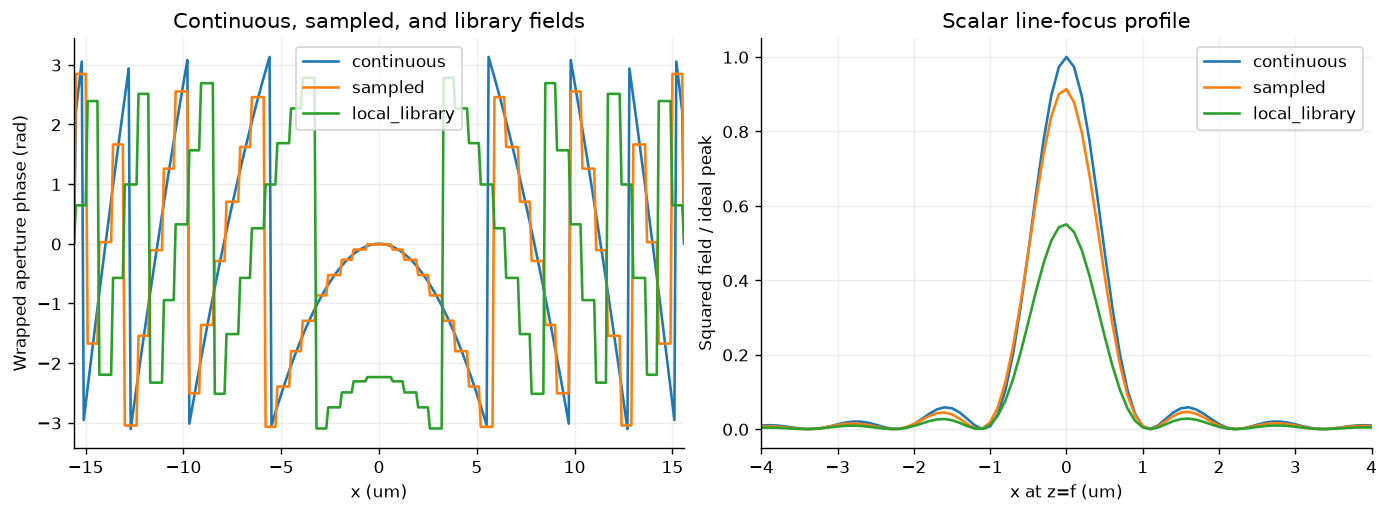

In [2]:
k=2*np.pi*OUTPUT_INDEX/WAVELENGTH_UM
cell_centers=(np.arange(N_APERTURE_CELLS)+.5)*PITCH_UM-APERTURE_UM/2
phase_cells=-k*(np.sqrt(cell_centers**2+FOCAL_DISTANCE_UM**2)-FOCAL_DISTANCE_UM)
choices=[]
for offset in np.linspace(-np.pi,np.pi,361,endpoint=False):
    selected,error=select_widths(rows,phase_cells,.8,float(offset))
    choices.append((float(np.mean(error**2)),float(offset),selected))
score,phase_offset,selected=min(choices,key=lambda v:v[0])
local_t=np.array([complex(r['t_real'],r['t_imag']) for r in selected])
def validate_focus_grid(dx,n):
    if not np.isfinite(dx) or dx<=0 or not isinstance(n,(int,np.integer)) or n<16 or n%2:
        raise ValueError('Use positive dx and an even integer FFT length of at least 16.')
    half_window=n*dx/2
    if dx>=WAVELENGTH_UM/(2*OUTPUT_INDEX):
        raise ValueError('The grid must resolve the propagating angular-spectrum band.')
    if APERTURE_UM/2+4*dx>=half_window:
        raise ValueError('The physical aperture must fit inside every padded FFT window.')
    if not 0<FOCUS_WINDOW_HALF_UM<FOCAL_COMPARE_HALF_UM<half_window-dx:
        raise ValueError('The fixed integration and comparison regions must fit in every grid without extrapolation.')

def aperture_fields(dx,n):
    validate_focus_grid(dx,n)
    x=(np.arange(n)-n//2)*dx
    gate=abs(x)<APERTURE_UM/2
    bins=np.clip(np.floor((x+APERTURE_UM/2)/PITCH_UM).astype(int),0,N_APERTURE_CELLS-1)
    continuous=np.where(gate,np.exp(-1j*k*(np.sqrt(x*x+FOCAL_DISTANCE_UM**2)-FOCAL_DISTANCE_UM)),0)
    sampled=np.where(gate,np.exp(1j*phase_cells[bins]),0)
    local=np.where(gate,local_t[bins],0)
    return x,dict(continuous=continuous,sampled=sampled,local_library=local)

def fixed_window_integral(x,intensity,half_width):
    """Trapezoidal integral with interpolated endpoints at the same physical +/- width."""
    if -half_width<x[0] or half_width>x[-1]:
        raise ValueError('Requested physical integration interval lies outside the FFT grid.')
    interior=(x>-half_width)&(x<half_width)
    coordinates=np.r_[-half_width,x[interior],half_width]
    values=np.r_[np.interp(-half_width,x,intensity),intensity[interior],np.interp(half_width,x,intensity)]
    return float(np.sum((values[1:]+values[:-1])*np.diff(coordinates)/2))

def focus_metrics(x,field):
    intensity=np.abs(field)**2
    peak=int(np.argmax(intensity))
    fwhm=float(line_fwhm(x,intensity))
    if not np.all(np.isfinite(intensity)) or intensity[peak]<=0 or not np.isfinite(fwhm):
        raise ValueError('Finite, nonzero focus and resolved half-maximum crossings are required.')
    if abs(x[peak])>=FOCAL_COMPARE_HALF_UM or fwhm>=2*FOCAL_COMPARE_HALF_UM:
        raise ValueError('The focal comparison interval does not contain the intended central focus.')
    window_integral=fixed_window_integral(x,intensity,FOCUS_WINDOW_HALF_UM)
    total_integral=float((x[1]-x[0])*np.sum(intensity))  # Periodic discrete norm, not a power-flux claim.
    return dict(fwhm_um=fwhm,peak_intensity=float(intensity[peak]),
                relative_peak=float(intensity[peak]/ideal_peak),
                fixed_window_line_intensity=window_integral,
                line_intensity_per_aperture=float(window_integral/APERTURE_UM),
                total_line_intensity=total_integral,
                line_intensity_fraction=float(window_integral/total_integral))

x,apertures=aperture_fields(DX_UM,N_FFT)
focus={name:angular_spectrum_1d(field,DX_UM,WAVELENGTH_UM,FOCAL_DISTANCE_UM,OUTPUT_INDEX) for name,field in apertures.items()}
# Freeze ONE peak normalization for every aperture model, window, and grid.
ideal_peak=float(np.max(abs(focus['continuous'])**2))
metrics=[dict(model=name,**focus_metrics(x,field)) for name,field in focus.items()]
table(['Scalar aperture model','FWHM (um)','Peak / fixed ideal peak','Fixed-window line intensity / aperture width','Fixed-window / total modeled line intensity'],
      [[r[key] for key in ['model','fwhm_um','relative_peak','line_intensity_per_aperture','line_intensity_fraction']] for r in metrics])
print('All fixed-window integrals use the same physical +/-',FOCUS_WINDOW_HALF_UM,'um boundaries, with interpolated endpoints.')
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for name,field in apertures.items():axes[0].plot(x,np.angle(field),label=name)
axes[0].set(xlim=(-APERTURE_UM/2,APERTURE_UM/2),xlabel='x (um)',ylabel='Wrapped aperture phase (rad)',title='Continuous, sampled, and library fields')
for name,field in focus.items():axes[1].plot(x,abs(field)**2/ideal_peak,label=name)
axes[1].set(xlim=(-4,4),xlabel='x at z=f (um)',ylabel='Squared field / ideal peak',title='Scalar line-focus profile')
for ax in axes:ax.grid(alpha=.2);ax.legend()
plt.show()

## 2. Validate scalar propagation

The FFT uses a periodic computational window. The window study holds sample spacing fixed, and the grid study holds the physical window fixed. Both regenerate **all three aperture models** with the same selected cells and unchanged physical aperture, focal distance, and integration region. The cache reuses shared configurations; no new Maxwell calculation is involved.

Every peak uses the original continuous-aperture peak as one frozen denominator. Fixed-window line intensity is integrated between the same physical endpoints with interpolation, then divided by the physical aperture width for an amplitude-sensitive scalar comparison. The separately reported concentration divides that same integral by each model's total modeled line intensity. FWHM uses each profile's own half maximum by definition. None of these scalar ratios is a physical focusing-power efficiency.

The tables retain every refinement, then check the final independent pair for each model: focal-profile change, relative FWHM change, peak change, fixed-window line-intensity change, and concentration change. Limits are declared in the code for this teaching experiment; passing them supports these observables over the tested refinements, not an exact continuum limit or a full-wave finite metalens. Domain guards reject an aperture/region that does not fit, extrapolation, unresolved propagating bandwidth, or a focus without resolved half-maximum crossings.

A homogeneous sampled plane wave also has an exact propagation phase, and retained propagating Fourier bins preserve the discrete field norm. Those limiting checks complement rather than replace the independent aperture refinements.


Study,Aperture,dx (um),Window (um),FWHM (um),Peak / fixed ideal peak,Fixed-window integral / aperture,Profile difference / fixed ideal peak
window,continuous,0.05,102.4,0.9708287,1.001901,0.8753731,0.0003984769
window,sampled,0.05,102.4,0.9931541,0.908187,0.8120216,0.003384838
window,local_library,0.05,102.4,0.996531,0.5467875,0.4901459,0.002652425
window,continuous,0.05,204.8,0.9698811,1.002519,0.8753143,0.0002198515
window,sampled,0.05,204.8,0.9809462,0.9153863,0.8115506,0.003814419
window,local_library,0.05,204.8,0.9834629,0.5514091,0.4898326,0.001969162
window,continuous,0.05,409.6,0.9702352,1.002299,0.8753363,0
window,sampled,0.05,409.6,0.9875528,0.9115719,0.8117807,0
window,local_library,0.05,409.6,0.989132,0.5494399,0.489954,0
grid,continuous,0.1,409.6,0.9714129,0.9994769,0.8737826,0.01155467


Last independent refinement,Aperture,Relative FWHM change,Peak change / fixed peak,Window-integral change / aperture,Concentration change,Pass
window,continuous,0.0003649237,0.0002198515,2.196085e-05,2.667442e-05,True
window,sampled,0.006689794,0.003814419,0.0002300919,0.0002703928,True
window,local_library,0.005731355,0.001969162,0.0001214257,0.0002338491,True
grid,continuous,0.0003567966,0.0007046777,0.0003495921,2.316306e-06,True
grid,sampled,0.0004833113,0.0006362978,0.0001825068,0.0001572878,True
grid,local_library,0.000491885,0.0003860321,0.0001113973,0.0001778744,True


Separate window/grid checks passed for continuous, sampled, and local-library apertures under the recorded demonstration tolerances.
Nominal focus: 30.0 um; sampled on-axis maximum: 29.75 um (finite-aperture focal shift is possible).


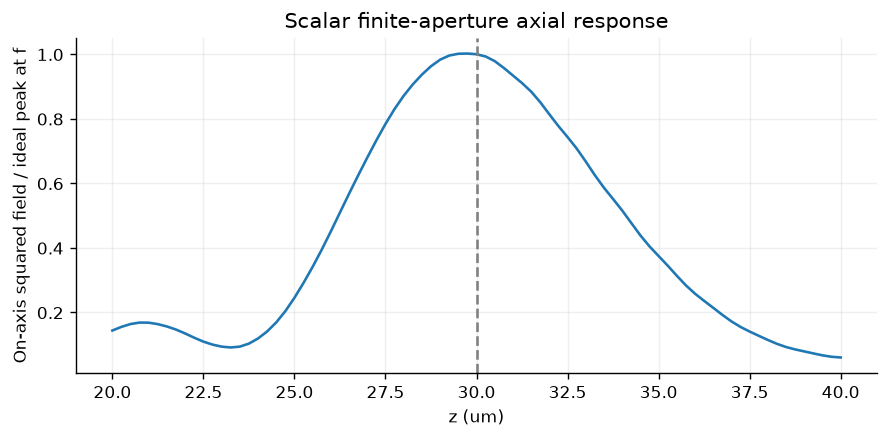

In [3]:
# Window changes at fixed dx; grid changes at fixed physical window.
# Every case regenerates all THREE aperture fields with the same selected cells.
study_specs=[('window',[(DX_UM/2,N_FFT),(DX_UM/2,2*N_FFT),(DX_UM/2,4*N_FFT)]),
             ('grid',[(DX_UM,2*N_FFT),(DX_UM/2,4*N_FFT),(DX_UM/4,8*N_FFT),(DX_UM/8,16*N_FFT)])]
comparison_x=np.linspace(-FOCAL_COMPARE_HALF_UM,FOCAL_COMPARE_HALF_UM,1601)
propagation_cache={}
def scalar_case(dx,n):
    key=(float(dx),int(n))
    if key not in propagation_cache:
        xr,fields=aperture_fields(dx,n)
        if comparison_x[0]<xr[0] or comparison_x[-1]>xr[-1]:
            raise ValueError('Do not extrapolate a focal profile beyond its physical FFT domain.')
        cases={}
        for name,field in fields.items():
            propagated=angular_spectrum_1d(field,dx,WAVELENGTH_UM,FOCAL_DISTANCE_UM,OUTPUT_INDEX)
            cases[name]=dict(metrics=focus_metrics(xr,propagated),
                             profile=np.interp(comparison_x,xr,np.abs(propagated)**2))
        propagation_cache[key]=cases
    return propagation_cache[key]

refinements=[];refinement_checks=[]
refinement_limits={
    'window':dict(profile_difference_over_fixed_peak=.02,relative_fwhm_change=.02,
                  peak_change_over_fixed_peak=.02,fixed_window_integral_change_over_aperture=.01,
                  line_concentration_change=.02),
    'grid':dict(profile_difference_over_fixed_peak=.03,relative_fwhm_change=.02,
                peak_change_over_fixed_peak=.03,fixed_window_integral_change_over_aperture=.02,
                line_concentration_change=.02)}
for study,specs in study_specs:
    fine_dx,fine_n=specs[-1]
    reference_cases=scalar_case(fine_dx,fine_n)
    for dx,n in specs:
        cases=scalar_case(dx,n)
        for name,case in cases.items():
            error=float(np.max(np.abs(case['profile']-reference_cases[name]['profile']))/ideal_peak)
            refinements.append(dict(study=study,model=name,dx_um=float(dx),fft_samples=int(n),
                                    window_um=float(dx*n),**case['metrics'],
                                    roi_peak_normalized_difference=error))
    coarse_dx,coarse_n=specs[-2]
    previous_cases=scalar_case(coarse_dx,coarse_n)
    for name,fine in reference_cases.items():
        previous=previous_cases[name];a=previous['metrics'];b=fine['metrics']
        changes=dict(profile_difference_over_fixed_peak=float(np.max(np.abs(previous['profile']-fine['profile']))/ideal_peak),
                     relative_fwhm_change=float(abs(a['fwhm_um']-b['fwhm_um'])/b['fwhm_um']),
                     peak_change_over_fixed_peak=float(abs(a['peak_intensity']-b['peak_intensity'])/ideal_peak),
                     fixed_window_integral_change_over_aperture=float(abs(a['line_intensity_per_aperture']-b['line_intensity_per_aperture'])),
                     line_concentration_change=float(abs(a['line_intensity_fraction']-b['line_intensity_fraction'])))
        passed=all(value<refinement_limits[study][key] for key,value in changes.items())
        refinement_checks.append(dict(study=study,model=name,
            compared_dx_um=[float(coarse_dx),float(fine_dx)],
            compared_windows_um=[float(coarse_dx*coarse_n),float(fine_dx*fine_n)],
            **changes,limits=refinement_limits[study],passed=bool(passed)))

table(['Study','Aperture','dx (um)','Window (um)','FWHM (um)','Peak / fixed ideal peak','Fixed-window integral / aperture','Profile difference / fixed ideal peak'],
      [[r[key] for key in ['study','model','dx_um','window_um','fwhm_um','relative_peak','line_intensity_per_aperture','roi_peak_normalized_difference']] for r in refinements])
table(['Last independent refinement','Aperture','Relative FWHM change','Peak change / fixed peak','Window-integral change / aperture','Concentration change','Pass'],
      [[r[key] for key in ['study','model','relative_fwhm_change','peak_change_over_fixed_peak','fixed_window_integral_change_over_aperture','line_concentration_change','passed']] for r in refinement_checks])
assert {(r['study'],r['model']) for r in refinement_checks}=={(s,m) for s in ['window','grid'] for m in apertures}
assert all(r['passed'] for r in refinement_checks), 'A scalar aperture refinement failed; inspect its recorded changes and retain the failed evidence.'
print('Separate window/grid checks passed for continuous, sampled, and local-library apertures under the recorded demonstration tolerances.')
mode=3;plane=np.exp(2j*np.pi*mode*np.arange(N_FFT)/N_FFT)
kx_mode=2*np.pi*mode/(N_FFT*DX_UM)
exact=plane*np.exp(1j*np.sqrt(k*k-kx_mode*kx_mode)*FOCAL_DISTANCE_UM)
propagated=angular_spectrum_1d(plane,DX_UM,WAVELENGTH_UM,FOCAL_DISTANCE_UM,OUTPUT_INDEX)
assert np.max(abs(propagated-exact))<1e-10
spectrum=np.zeros(N_FFT,complex);spectrum[[0,2,7,-3]]=[1,2j,.4,1-.2j]
test=np.fft.ifft(spectrum);after=angular_spectrum_1d(test,DX_UM,WAVELENGTH_UM,FOCAL_DISTANCE_UM,OUTPUT_INDEX)
assert abs(np.linalg.norm(after)-np.linalg.norm(test))<1e-12
z_scan=np.linspace(20,40,81)
axial=np.array([abs(angular_spectrum_1d(apertures['continuous'],DX_UM,WAVELENGTH_UM,float(z),OUTPUT_INDEX)[N_FFT//2])**2 for z in z_scan])
print('Nominal focus:',FOCAL_DISTANCE_UM,'um; sampled on-axis maximum:',z_scan[np.argmax(axial)],'um (finite-aperture focal shift is possible).')
fig,ax=plt.subplots(figsize=(7,3.4),layout='constrained');ax.plot(z_scan,axial/ideal_peak);ax.axvline(FOCAL_DISTANCE_UM,color='gray',ls='--');ax.set(xlabel='z (um)',ylabel='On-axis squared field / ideal peak at f',title='Scalar finite-aperture axial response');ax.grid(alpha=.2);plt.show()

## 3. Jones matrices and geometric phase

Define $\mathbf e_\sigma=(1,i\sigma)^T/\sqrt2$ in the fixed laboratory basis,
$\sigma=\pm1$. Use

$$
J(\theta)=R(\theta)\,\mathrm{diag}(t_x,t_y)R(-\theta).
$$

Then
the same-basis coefficient is $(t_x+t_y)/2$, and conversion to
$\mathbf e_{-\sigma}$ has coefficient
$(t_x-t_y)e^{2i\sigma\theta}/2$. An ideal half-wave element $t_x=1,t_y=-1$
therefore converts fully and contributes phase $2\sigma\theta$.

For a lossless retarder with $t_x=e^{i\delta/2}$, $t_y=e^{-i\delta/2}$, the
converted fraction is $\sin^2(\delta/2)$. A rotation angle alone does not
guarantee a large converted amplitude. The ideal analytical Jones model here
has a common medium and does not describe the TE ridge's vector response.

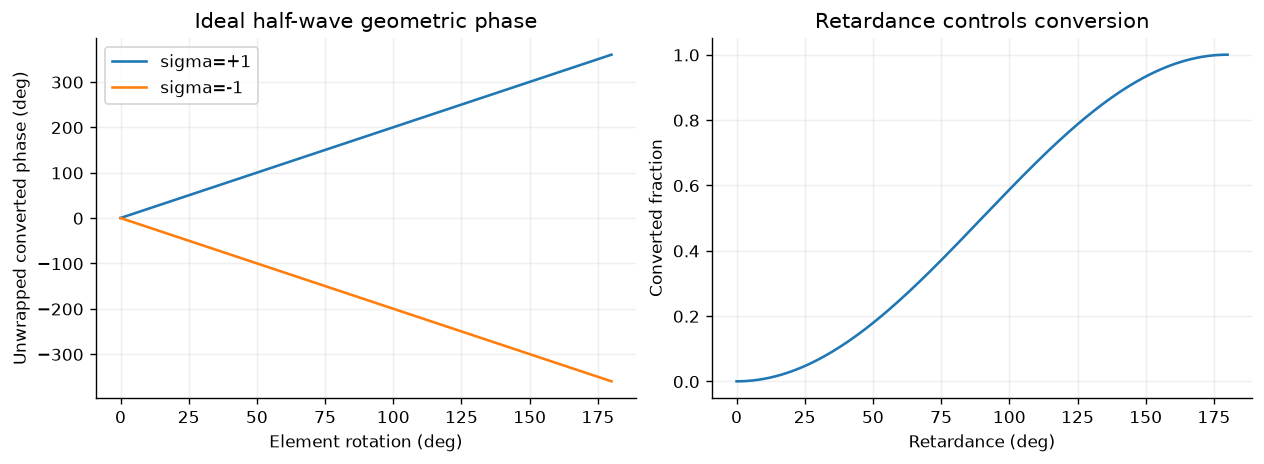

In [4]:
angles=np.linspace(0,np.pi,181);retardances=np.linspace(0,np.pi,181)
phase_curves=[];max_jones_error=0.
for sigma in [1,-1]:
    incident=np.array([1,1j*sigma])/np.sqrt(2);converted=np.array([1,-1j*sigma])/np.sqrt(2)
    amplitude=[]
    for theta in angles:
        J=rotated_jones(1.,-1.,float(theta));a=np.vdot(converted,J@incident)
        max_jones_error=max(max_jones_error,float(abs(a-np.exp(2j*sigma*theta))),float(np.linalg.norm(J.conj().T@J-np.eye(2))))
        amplitude.append(a)
    phase_curves.append(np.unwrap(np.angle(amplitude)))
converted_power=[]
incident=np.array([1,1j])/np.sqrt(2);opposite=np.array([1,-1j])/np.sqrt(2)
for delta in retardances:
    J=rotated_jones(np.exp(.5j*delta),np.exp(-.5j*delta),.37)
    converted_power.append(abs(np.vdot(opposite,J@incident))**2)
assert max_jones_error<1e-12
assert max(abs(np.array(converted_power)-np.sin(retardances/2)**2))<1e-12
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for sigma,phase in zip([1,-1],phase_curves):axes[0].plot(np.rad2deg(angles),np.rad2deg(phase),label=f'sigma={sigma:+d}')
axes[0].set(xlabel='Element rotation (deg)',ylabel='Unwrapped converted phase (deg)',title='Ideal half-wave geometric phase');axes[0].legend()
axes[1].plot(np.rad2deg(retardances),converted_power);axes[1].set(xlabel='Retardance (deg)',ylabel='Converted fraction',title='Retardance controls conversion')
for ax in axes:ax.grid(alpha=.2)
plt.show()

## 4. Save model boundaries with the metrics

FWHM and the fraction of modeled line intensity within a specified window are
scalar line-focus metrics. They are not a measured or full-wave focusing
efficiency, a two-dimensional encircled-energy metric, or proof of a fabricated
metalens. Physical dispersion, off-axis aberrations, fabrication tolerance,
polarization leakage, and finite-device Maxwell validation require extensions.

In [5]:
summary=dict(model='1D scalar angular spectrum plus separate analytical Jones matrices',aperture_um=APERTURE_UM,focal_distance_um=FOCAL_DISTANCE_UM,wavelength_um=WAVELENGTH_UM,output_index=OUTPUT_INDEX,dx_um=DX_UM,fft_samples=N_FFT,window_um=DX_UM*N_FFT,focus_window_half_um=FOCUS_WINDOW_HALF_UM,metrics=metrics,refinements=refinements,refinement_checks=refinement_checks,focus_comparison_half_um=FOCAL_COMPARE_HALF_UM,metric_normalization=dict(peak='one frozen baseline continuous-aperture peak',fixed_window='same physical endpoints integrated with interpolation',line_intensity='fixed-window integral divided by physical aperture width',concentration='fixed-window integral divided by each model total line intensity',scope='scalar squared-field metrics, not electromagnetic focusing efficiency'),axial_peak_um=float(z_scan[np.argmax(axial)]),max_jones_error=max_jones_error,library_phase_rms_deg=float(np.rad2deg(np.sqrt(score))),source_sha256=hashlib.sha256((ROOT/'simulations/metasurface_synthesis.py').read_bytes()).hexdigest(),limitations=['Cylindrical scalar focus, not a full-wave metalens','Library aperture uses local periodicity','Jones matrices are ideal analytical elements, not the TE ridge','No physical focusing efficiency is reported'])
(DATA/'wavefront-models.json').write_text(json.dumps(summary,indent=2)+'\n',encoding='utf-8')
print('Saved wavefront-models.json; model checks passed.')

Saved wavefront-models.json; model checks passed.


Exercises: change focal distance and aperture width; repeat window/grid checks.
Calculate the maximum phase step and discuss spatial sampling. Compare exact
and paraxial target phases. Add amplitude apodization and quantify the scalar
peak/width/sidelobe tradeoff using a stated normalization. Change Jones
retardance and distinguish phase coverage from conversion amplitude.

Reference: [Arbabi et al., dielectric phase/polarization control](https://doi.org/10.1038/nnano.2015.186).
The ridge supercell, scalar focusing model, and analytical Jones model supply
different kinds of evidence and should remain labeled in any report.